# KI-Labor – Assignment 7: RNN vs. DistilBERT (TweetEval Emotion)

In [1]:
import os
import random
import shutil
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import Dataset, DatasetDict
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          PrinterCallback, Trainer, TrainerCallback, TrainingArguments, set_seed)
import transformers

import datasets

transformers.logging.set_verbosity_error()  # Lade-Report/Warnungen ausblenden
transformers.logging.disable_progress_bar()
datasets.disable_progress_bars()
SEED = 42
set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
print(f"PyTorch {torch.__version__} | transformers {transformers.__version__} | Gerät: {DEVICE} ({GPU_NAME})")

/home/debian/jupyter-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.14.1+cu130 | transformers 5.22.2 | Gerät: cuda (NVIDIA GeForce RTX 5060 Ti)


## 1. Daten laden (identischer Split wie in Assignment 6)

In [2]:
DATA_DIR = "../assignment6/tweeteval/datasets/emotion"


def read_lines(name):
    with open(os.path.join(DATA_DIR, name), encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f]


with open(os.path.join(DATA_DIR, "mapping.txt")) as f:
    CLASSES = [line.split("\t")[1].strip() for line in f if line.strip()]
NUM_CLASSES = len(CLASSES)
id2label = dict(enumerate(CLASSES))
label2id = {c: i for i, c in id2label.items()}


def preprocess(text):
    # gleiche Normalisierung wie in Assignment 6 / TweetEval-Tutorial
    new_text = []
    for t in text.split(" "):
        t = "@user" if t.startswith("@") and len(t) > 1 else t
        t = "http" if t.startswith("http") else t
        new_text.append(t)
    return " ".join(new_text)


splits = {}
for split in ["train", "val", "test"]:
    texts = read_lines(f"{split}_text.txt")
    labels = [int(x) for x in read_lines(f"{split}_labels.txt")]
    assert len(texts) == len(labels)
    splits[split] = (texts, labels)

raw = DatasetDict({s: Dataset.from_dict({"text": [preprocess(t) for t in tx], "label": lb})
                   for s, (tx, lb) in splits.items()})
print("Klassen:", CLASSES)
print(raw)
for split, (texts, labels) in splits.items():
    counts = np.bincount(labels, minlength=NUM_CLASSES)
    print(f"{split:5s}: " + ", ".join(f"{c}={n} ({n / len(labels):.0%})" for c, n in zip(CLASSES, counts)))

Klassen: ['anger', 'joy', 'optimism', 'sadness']
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 3257
    })
    val: Dataset({
        features: ['text', 'label'],
        num_rows: 374
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1421
    })
})
train: anger=1400 (43%), joy=708 (22%), optimism=294 (9%), sadness=855 (26%)
val  : anger=160 (43%), joy=97 (26%), optimism=28 (7%), sadness=89 (24%)
test : anger=558 (39%), joy=358 (25%), optimism=123 (9%), sadness=382 (27%)


## 2. Tokenisierung mit dem DistilBERT-Tokenizer

In [3]:
MODEL_NAME = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = raw["train"][1]["text"]
enc = tokenizer(example)
print("Text:          ", example)
print("Tokens:        ", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("input_ids:     ", enc["input_ids"])
print("attention_mask:", enc["attention_mask"])
print(f"Vokabulargröße: {tokenizer.vocab_size:,} | max. Länge: {tokenizer.model_max_length}")


def tokenize_fn(batch):
    return tokenizer(batch["text"], truncation=True)


tokenized = raw.map(tokenize_fn, batched=True, remove_columns=["text"])
lengths = np.array([len(x) for x in tokenized["train"]["input_ids"]])
unk_rate = {s: np.mean([i == tokenizer.unk_token_id for ids in tokenized[s]["input_ids"] for i in ids])
            for s in ["val", "test"]}
print(f"\nSubword-Tokens pro Tweet (Train, inkl. [CLS]/[SEP]): Median {np.median(lengths):.0f}, "
      f"Max {lengths.max()} → keine Kürzung nötig (Limit 512)")
unk_words = Counter(w for t in raw["test"]["text"] for w in t.split() if tokenizer.unk_token in tokenizer.tokenize(w))
print("[UNK]-Anteil:", {k: f"{v:.2%}" for k, v in unk_rate.items()}, "(Assignment 6: ~19 % <unk>)")
print("Häufigste [UNK]-Wörter im Test:", unk_words.most_common(10))

collator = DataCollatorWithPadding(tokenizer=tokenizer)
batch = collator([tokenized["train"][i] for i in range(3)])
print("\nDynamisch gepaddeter Batch:", {k: tuple(v.shape) for k, v in batch.items()})
print("attention_mask (0 = Padding):\n", batch["attention_mask"])

Text:           My roommate: it's okay that we can't spell because we have autocorrect. #terrible #firstworldprobs 
Tokens:         ['[CLS]', 'my', 'roommate', ':', 'it', "'", 's', 'okay', 'that', 'we', 'can', "'", 't', 'spell', 'because', 'we', 'have', 'auto', '##cor', '##re', '##ct', '.', '#', 'terrible', '#', 'first', '##world', '##pro', '##bs', '[SEP]']
input_ids:      [101, 2026, 18328, 1024, 2009, 1005, 1055, 3100, 2008, 2057, 2064, 1005, 1056, 6297, 2138, 2057, 2031, 8285, 27108, 2890, 6593, 1012, 1001, 6659, 1001, 2034, 11108, 21572, 5910, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Vokabulargröße: 30,522 | max. Länge: 512



Subword-Tokens pro Tweet (Train, inkl. [CLS]/[SEP]): Median 26, Max 62 → keine Kürzung nötig (Limit 512)


[UNK]-Anteil: {'val': '1.30%', 'test': '1.06%'} (Assignment 6: ~19 % <unk>)
Häufigste [UNK]-Wörter im Test: [('😂', 30), ('😭', 22), ('😢', 10), ('😠', 9), ('😄', 9), ('🙃', 8), ('😡', 8), ('🤣', 8), ('😍', 7), ('😅', 7)]

Dynamisch gepaddeter Batch: {'input_ids': (3, 30), 'token_type_ids': (3, 30), 'attention_mask': (3, 30), 'labels': (3,)}
attention_mask (0 = Padding):
 tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 0, 0, 0, 0, 0]])


## 4. Modell: vortrainierter DistilBERT-Encoder + Klassifikationskopf

In [4]:
def build_model():
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_CLASSES, id2label=id2label, label2id=label2id)


model = build_model()
n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_head = sum(p.numel() for n, p in model.named_parameters() if n.startswith(("pre_classifier", "classifier")))
n_emb = sum(p.numel() for p in model.distilbert.embeddings.parameters())
print(f"Parameter gesamt:     {n_total:,}")
print(f"davon trainierbar:    {n_train:,} (vollständiges Fine-Tuning, nichts eingefroren)")
print(f"davon Embeddings:     {n_emb:,} (Token- + Positions-Embeddings)")
print(f"davon Klassifikator:  {n_head:,} (neu initialisiert)")
print(f"Speicher (fp32):      {n_total * 4 / 1e6:.0f} MB")
del model

Parameter gesamt:     66,956,548
davon trainierbar:    66,956,548 (vollständiges Fine-Tuning, nichts eingefroren)
davon Embeddings:     23,835,648 (Token- + Positions-Embeddings)
davon Klassifikator:  593,668 (neu initialisiert)
Speicher (fp32):      268 MB


## 4. Fine-Tuning mit `Trainer`

In [5]:
BATCH_SIZE = 16
EPOCHS = 5
LEARNING_RATES = [2e-5, 5e-5]
RUN_DIR = "./runs"


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1": f1_score(labels, preds, average="macro")}


class TrainEvalCallback(TrainerCallback):
    # wertet am Epochenende zusätzlich das Trainingsset aus (Loss/Accuracy für die Lernkurven)
    def __init__(self, trainer):
        self.trainer = trainer

    def on_epoch_end(self, args, state, control, **kwargs):
        # evaluate() setzt die Flags des Trainers zurück → sichern und wiederherstellen
        flags = (control.should_evaluate, control.should_log, control.should_save)
        self.trainer.evaluate(self.trainer.train_dataset, metric_key_prefix="train_eval")
        control.should_evaluate, control.should_log, control.should_save = flags
        return control


def finetune(lr, seed=SEED, epochs=EPOCHS, track_train=True):
    set_seed(seed)
    out = os.path.join(RUN_DIR, f"lr{lr:g}_seed{seed}")
    args = TrainingArguments(
        output_dir=out,
        learning_rate=lr,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=128,
        num_train_epochs=epochs,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        save_total_limit=1,
        save_only_model=True,
        seed=seed,
        report_to="none",
        disable_tqdm=True,
    )
    trainer = Trainer(model=build_model(), args=args, train_dataset=tokenized["train"],
                      eval_dataset=tokenized["val"], processing_class=tokenizer,
                      data_collator=collator, compute_metrics=compute_metrics)
    trainer.remove_callback(PrinterCallback)  # keine rohen Log-Dicts ausgeben
    if track_train:
        trainer.add_callback(TrainEvalCallback(trainer))
    start = time.perf_counter()
    trainer.train()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    duration = time.perf_counter() - start
    shutil.rmtree(out, ignore_errors=True)  # Checkpoints (je ~270 MB) nicht aufbewahren

    logs = trainer.state.log_history
    hist = {
        "train_loss": [l["loss"] for l in logs if "loss" in l and "epoch" in l and "eval_loss" not in l],
        "train_eval_loss": [l["train_eval_loss"] for l in logs if "train_eval_loss" in l],
        "train_acc": [l["train_eval_accuracy"] for l in logs if "train_eval_accuracy" in l],
        "val_loss": [l["eval_loss"] for l in logs if "eval_loss" in l],
        "val_acc": [l["eval_accuracy"] for l in logs if "eval_accuracy" in l],
        "val_f1": [l["eval_f1"] for l in logs if "eval_f1" in l],
    }
    best_epoch = int(np.argmax(hist["val_f1"])) + 1
    return trainer, hist, best_epoch, duration


sweep = {}
for lr in LEARNING_RATES:
    trainer, hist, best_epoch, duration = finetune(lr)
    sweep[lr] = dict(trainer=trainer, history=hist, best_epoch=best_epoch, time=duration)
    for e in range(EPOCHS):
        print(f"[lr={lr:g}] Epoche {e + 1} | Train-Loss {hist['train_loss'][e]:.3f}, Acc {hist['train_acc'][e]:.3f} | "
              f"Val-Loss {hist['val_loss'][e]:.3f}, Acc {hist['val_acc'][e]:.3f}, F1 {hist['val_f1'][e]:.3f}")
    print(f"[lr={lr:g}] Trainingszeit {duration:.1f} s (inkl. Train-Auswertung) | "
          f"bester Val-F1 {max(hist['val_f1']):.3f} in Epoche {best_epoch}\n")

[lr=2e-05] Epoche 1 | Train-Loss 0.921, Acc 0.833 | Val-Loss 0.638, Acc 0.775, F1 0.694
[lr=2e-05] Epoche 2 | Train-Loss 0.514, Acc 0.898 | Val-Loss 0.638, Acc 0.762, F1 0.697
[lr=2e-05] Epoche 3 | Train-Loss 0.342, Acc 0.938 | Val-Loss 0.669, Acc 0.775, F1 0.719
[lr=2e-05] Epoche 4 | Train-Loss 0.224, Acc 0.960 | Val-Loss 0.699, Acc 0.778, F1 0.712
[lr=2e-05] Epoche 5 | Train-Loss 0.166, Acc 0.968 | Val-Loss 0.727, Acc 0.775, F1 0.708
[lr=2e-05] Trainingszeit 37.1 s (inkl. Train-Auswertung) | bester Val-F1 0.719 in Epoche 3



[lr=5e-05] Epoche 1 | Train-Loss 0.822, Acc 0.866 | Val-Loss 0.607, Acc 0.794, F1 0.723
[lr=5e-05] Epoche 2 | Train-Loss 0.427, Acc 0.943 | Val-Loss 0.648, Acc 0.794, F1 0.724
[lr=5e-05] Epoche 3 | Train-Loss 0.209, Acc 0.975 | Val-Loss 0.873, Acc 0.754, F1 0.699
[lr=5e-05] Epoche 4 | Train-Loss 0.104, Acc 0.988 | Val-Loss 0.946, Acc 0.781, F1 0.722
[lr=5e-05] Epoche 5 | Train-Loss 0.054, Acc 0.991 | Val-Loss 0.989, Acc 0.791, F1 0.729
[lr=5e-05] Trainingszeit 36.7 s (inkl. Train-Auswertung) | bester Val-F1 0.729 in Epoche 5



In [6]:
best_lr = max(sweep, key=lambda lr: max(sweep[lr]["history"]["val_f1"]))
best = sweep[best_lr]
for lr in sweep:
    if lr != best_lr:
        sweep[lr]["trainer"].model.cpu()
torch.cuda.empty_cache()
print(f"Gewählt (nur nach Validierung): lr={best_lr:g}, Epoche {best['best_epoch']} "
      f"(Val-F1 {max(best['history']['val_f1']):.3f})")

Gewählt (nur nach Validierung): lr=5e-05, Epoche 5 (Val-F1 0.729)


## 6. Lernkurven

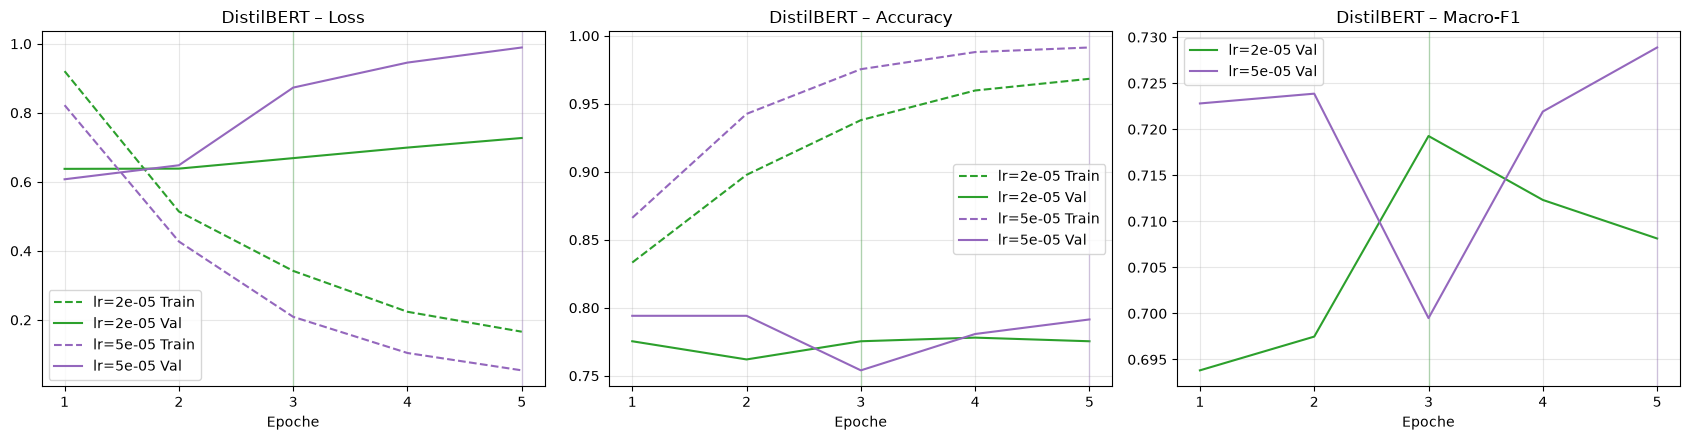

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
epochs = range(1, EPOCHS + 1)
colors = dict(zip(LEARNING_RATES, ["tab:green", "tab:purple"]))
for lr, res in sweep.items():
    h, c = res["history"], colors[lr]
    axes[0].plot(epochs, h["train_loss"], c=c, ls="--", label=f"lr={lr:g} Train")
    axes[0].plot(epochs, h["val_loss"], c=c, label=f"lr={lr:g} Val")
    axes[1].plot(epochs, h["train_acc"], c=c, ls="--", label=f"lr={lr:g} Train")
    axes[1].plot(epochs, h["val_acc"], c=c, label=f"lr={lr:g} Val")
    axes[2].plot(epochs, h["val_f1"], c=c, label=f"lr={lr:g} Val")
    for ax in axes:
        ax.axvline(res["best_epoch"], c=c, alpha=0.3, lw=1)
for ax, title in zip(axes, ["Loss", "Accuracy", "Macro-F1"]):
    ax.set_title(f"DistilBERT – {title}")
    ax.set_xlabel("Epoche")
    ax.set_xticks(list(epochs))
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Einmalige Auswertung auf dem Testset

In [8]:
@torch.no_grad()
def predict(model, dataset, batch_size=128, device=DEVICE):
    model.eval().to(device)
    loader = torch.utils.data.DataLoader(dataset.remove_columns(["label"]), batch_size=batch_size,
                                         collate_fn=collator)
    logits = []
    for b in loader:
        logits.append(model(**{k: v.to(device) for k, v in b.items()}).logits.float().cpu())
    return torch.cat(logits)


def timed_predict(model, dataset, device, repeats=3, **kw):
    predict(model, dataset.select(range(64)), device=device, **kw)  # Warm-up
    times = []
    for _ in range(repeats):
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        logits = predict(model, dataset, device=device, **kw)
        if device.type == "cuda":
            torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return logits, min(times)


bert_model = best["trainer"].model
test_logits, t_gpu = timed_predict(bert_model, tokenized["test"], DEVICE)
test_preds = test_logits.argmax(1).numpy()
test_targets = np.array(splits["test"][1])

bert_test = {
    "acc": accuracy_score(test_targets, test_preds),
    "f1": f1_score(test_targets, test_preds, average="macro"),
    "per_class": f1_score(test_targets, test_preds, average=None),
    "preds": test_preds,
}
majority = np.bincount(splits["train"][1]).argmax()
print(f"Baseline (immer '{CLASSES[majority]}'): Accuracy {np.mean(test_targets == majority):.3f}")
print(f"DistilBERT Test-Acc {bert_test['acc']:.3f} | Macro-F1 {bert_test['f1']:.3f} | "
      + ", ".join(f"F1 {c} {f:.3f}" for c, f in zip(CLASSES, bert_test["per_class"])))

Baseline (immer 'anger'): Accuracy 0.393
DistilBERT Test-Acc 0.799 | Macro-F1 0.763 | F1 anger 0.843, F1 joy 0.805, F1 optimism 0.617, F1 sadness 0.787


### Inferenzzeit

In [9]:
cpu = torch.device("cpu")
_, t_cpu = timed_predict(bert_model, tokenized["test"], cpu, repeats=1)
bert_model.to(DEVICE)
n_test = len(test_targets)
print(f"GPU ({GPU_NAME}): {t_gpu:.2f} s für {n_test} Tweets → {n_test / t_gpu:,.0f} Tweets/s")
print(f"CPU ({os.cpu_count()} Threads): {t_cpu:.2f} s für {n_test} Tweets → {n_test / t_cpu:,.0f} Tweets/s")

GPU (NVIDIA GeForce RTX 5060 Ti): 0.65 s für 1421 Tweets → 2,199 Tweets/s
CPU (12 Threads): 11.06 s für 1421 Tweets → 128 Tweets/s


### Fairer Zeitvergleich auf der CPU

In [10]:
import re
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence

# --- DistilBERT: 1 Epoche Fine-Tuning auf der CPU ---
torch.manual_seed(SEED)
cpu_model = build_model().to(cpu).train()
opt = torch.optim.AdamW(cpu_model.parameters(), lr=best_lr, weight_decay=0.01)
train_loader = torch.utils.data.DataLoader(tokenized["train"], batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator)
t0 = time.perf_counter()
for b in train_loader:
    loss = cpu_model(**b).loss
    opt.zero_grad()
    loss.backward()
    opt.step()
t_epoch_cpu = time.perf_counter() - t0
del cpu_model, opt
print(f"DistilBERT CPU-Training: {t_epoch_cpu:.0f} s pro Epoche → ≈ {t_epoch_cpu * EPOCHS / 60:.1f} min für {EPOCHS} Epochen")

# --- RNN-Architektur aus Assignment 6 (untrainiert, nur Laufzeit) ---
TOKEN_RE = re.compile(r"[#@]?\w+(?:['’]\w+)*|[^\w\s]")
tok6 = lambda t: TOKEN_RE.findall(t.lower())
counter6 = Counter(w for t in raw["train"]["text"] for w in tok6(t))
stoi6 = {w: i + 2 for i, (w, _) in enumerate(counter6.most_common(3000))}
test_ids6 = [torch.tensor([stoi6.get(w, 1) for w in tok6(t)] or [1]) for t in raw["test"]["text"]]


class RNNClassifier(nn.Module):  # identisch zu Assignment 6
    def __init__(self, cell):
        super().__init__()
        self.cell = cell
        self.embedding = nn.Embedding(3002, 128, padding_idx=0)
        self.rnn = {"lstm": nn.LSTM, "gru": nn.GRU}[cell](128, 256, batch_first=True)
        self.fc = nn.Linear(256, NUM_CLASSES)

    def forward(self, ids, lengths):
        packed = pack_padded_sequence(self.embedding(ids), lengths, batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        return self.fc((h[0] if self.cell == "lstm" else h)[-1])


@torch.no_grad()
def rnn_inference_time(model, repeats=3):
    model.eval()
    times = []
    for _ in range(repeats + 1):  # erster Lauf = Warm-up
        t0 = time.perf_counter()
        for i in range(0, len(test_ids6), 128):
            seqs = test_ids6[i:i + 128]
            model(pad_sequence(seqs, batch_first=True), torch.tensor([len(s) for s in seqs]))
        times.append(time.perf_counter() - t0)
    return min(times[1:])


infer_cpu = {cell.upper(): rnn_inference_time(RNNClassifier(cell)) for cell in ["lstm", "gru"]}
infer_cpu["DistilBERT"] = t_cpu
for name, t in infer_cpu.items():
    print(f"Inferenz Testset auf CPU – {name:10s}: {t:6.2f} s → {n_test / t:7,.0f} Tweets/s")

DistilBERT CPU-Training: 102 s pro Epoche → ≈ 8.5 min für 5 Epochen


Inferenz Testset auf CPU – LSTM      :   0.09 s →  16,149 Tweets/s
Inferenz Testset auf CPU – GRU       :   0.07 s →  21,848 Tweets/s
Inferenz Testset auf CPU – DistilBERT:  11.06 s →     128 Tweets/s


### Robustheit: mehrere Seeds (gleiche Konfiguration)

In [11]:
SEEDS = [0, 1, 2, 3, 4]
bert_seed_scores, bert_seed_times = [], []
for seed in SEEDS:
    tr, hist, be, dur = finetune(best_lr, seed=seed, track_train=False)
    p = predict(tr.model, tokenized["test"]).argmax(1).numpy()
    bert_seed_scores.append((accuracy_score(test_targets, p), f1_score(test_targets, p, average="macro")))
    bert_seed_times.append(dur)
    print(f"Seed {seed}: beste Epoche {be}, Trainingszeit {dur:.0f} s | Test-Acc {bert_seed_scores[-1][0]:.3f}, "
          f"F1 {bert_seed_scores[-1][1]:.3f}")
    del tr
    torch.cuda.empty_cache()
shutil.rmtree(RUN_DIR, ignore_errors=True)
acc, f1 = np.array(bert_seed_scores).T
print(f"\nReine Trainingszeit (5 Epochen, ohne Train-Auswertung): {np.mean(bert_seed_times):.1f} s auf der GPU")
print(f"DistilBERT: Test-Acc {acc.mean():.3f} ± {acc.std():.3f} | Macro-F1 {f1.mean():.3f} ± {f1.std():.3f}")

Seed 0: beste Epoche 5, Trainingszeit 29 s | Test-Acc 0.797, F1 0.755


Seed 1: beste Epoche 4, Trainingszeit 29 s | Test-Acc 0.795, F1 0.756


Seed 2: beste Epoche 3, Trainingszeit 38 s | Test-Acc 0.797, F1 0.763


Seed 3: beste Epoche 5, Trainingszeit 29 s | Test-Acc 0.798, F1 0.755


Seed 4: beste Epoche 2, Trainingszeit 30 s | Test-Acc 0.791, F1 0.750

Reine Trainingszeit (5 Epochen, ohne Train-Auswertung): 31.1 s auf der GPU
DistilBERT: Test-Acc 0.796 ± 0.003 | Macro-F1 0.756 ± 0.004


## 8. Vergleich mit Assignment 6 (LSTM/GRU – Ergebnisse übernommen, nicht neu trainiert)

In [12]:
A6 = {  # aus assignment6.ipynb (Seed 42 bzw. Seeds 0–4)
    "LSTM": dict(acc=0.574, f1=0.503, per_class=[0.666, 0.523, 0.278, 0.547], params=780_548, best_epoch=10,
                 epochs=15, batch=32, lr="1e-03", time=21.6, device="CPU", seeds=(0.588, 0.012, 0.520, 0.011)),
    "GRU": dict(acc=0.601, f1=0.528, per_class=[0.673, 0.574, 0.265, 0.599], params=681_732, best_epoch=10,
                epochs=15, batch=32, lr="1e-03", time=19.3, device="CPU", seeds=(0.601, 0.007, 0.537, 0.008)),
}
A6_PREDS_AVAILABLE = False
rows = dict(A6)
rows["DistilBERT"] = dict(acc=bert_test["acc"], f1=bert_test["f1"], per_class=list(bert_test["per_class"]),
                          params=n_total, best_epoch=best["best_epoch"], epochs=EPOCHS, batch=BATCH_SIZE,
                          lr=f"{best_lr:.0e}", time=np.mean(bert_seed_times), device="GPU",
                          seeds=(acc.mean(), acc.std(), f1.mean(), f1.std()))

header = (f"{'Modell':10s} | {'Acc':>5s} | {'M-F1':>5s} | " + " | ".join(f"{c[:8]:>8s}" for c in CLASSES)
          + f" | {'Acc (5 Seeds)':>13s} | {'F1 (5 Seeds)':>13s} | {'Parameter':>11s} | Ep.   | Batch | LR    | Training     | Inferenz CPU")
print(header)
print("-" * len(header))
for name, r in rows.items():
    s = r["seeds"]
    print(f"{name:10s} | {r['acc']:.3f} | {r['f1']:.3f} | " + " | ".join(f"{f:8.3f}" for f in r["per_class"])
          + f" | {s[0]:.3f} ± {s[1]:.3f} | {s[2]:.3f} ± {s[3]:.3f} | {r['params']:>11,} | {r['best_epoch']:>2d}/{r['epochs']:<2d} "
          + f"| {r['batch']:>5d} | {r['lr']:5s} | {r['time']:5.1f} s {r['device']:3s} | {infer_cpu[name]:.2f} s")
print(f"\nDistilBERT-Training auf der CPU (hochgerechnet): ≈ {t_epoch_cpu * EPOCHS:.0f} s für {EPOCHS} Epochen")
print("Ep. = beste Epoche / trainierte Epochen; Training = Gesamtzeit aller Epochen")

Modell     |   Acc |  M-F1 |    anger |      joy | optimism |  sadness | Acc (5 Seeds) |  F1 (5 Seeds) |   Parameter | Ep.   | Batch | LR    | Training     | Inferenz CPU
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------
LSTM       | 0.574 | 0.503 |    0.666 |    0.523 |    0.278 |    0.547 | 0.588 ± 0.012 | 0.520 ± 0.011 |     780,548 | 10/15 |    32 | 1e-03 |  21.6 s CPU | 0.09 s
GRU        | 0.601 | 0.528 |    0.673 |    0.574 |    0.265 |    0.599 | 0.601 ± 0.007 | 0.537 ± 0.008 |     681,732 | 10/15 |    32 | 1e-03 |  19.3 s CPU | 0.07 s
DistilBERT | 0.799 | 0.763 |    0.843 |    0.805 |    0.617 |    0.787 | 0.796 ± 0.003 | 0.756 ± 0.004 |  66,956,548 |  5/5  |    16 | 5e-05 |  31.1 s GPU | 11.06 s

DistilBERT-Training auf der CPU (hochgerechnet): ≈ 512 s für 5 Epochen
Ep. = beste Epoche / trainierte Epochen; Training = Gesamtzeit aller Epochen


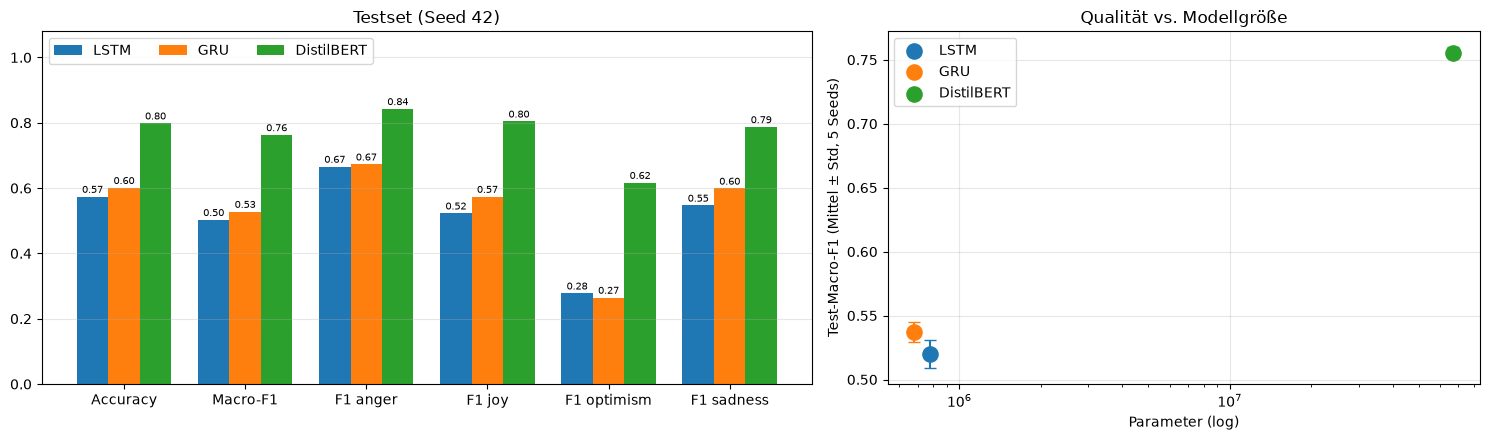

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
names = list(rows)
cols = ["tab:blue", "tab:orange", "tab:green"]
width = 0.26
x = np.arange(NUM_CLASSES + 2)
for i, (name, c) in enumerate(zip(names, cols)):
    r = rows[name]
    vals = [r["acc"], r["f1"]] + list(r["per_class"])
    bars = axes[0].bar(x + (i - 1) * width, vals, width, color=c, label=name)
    axes[0].bar_label(bars, fmt="%.2f", fontsize=7, padding=1)
axes[0].set_xticks(x, ["Accuracy", "Macro-F1"] + [f"F1 {c}" for c in CLASSES])
axes[0].set_ylim(0, 1.08)
axes[0].set_title("Testset (Seed 42)")
axes[0].legend(loc="upper left", ncols=3)
axes[0].grid(axis="y", alpha=0.3)

for name, c in zip(names, cols):
    r = rows[name]
    axes[1].scatter(r["params"], r["seeds"][2], s=120, color=c, label=name, zorder=3)
    axes[1].errorbar(r["params"], r["seeds"][2], yerr=r["seeds"][3], color=c, capsize=4)
axes[1].set_xscale("log")
axes[1].set_xlabel("Parameter (log)")
axes[1].set_ylabel("Test-Macro-F1 (Mittel ± Std, 5 Seeds)")
axes[1].set_title("Qualität vs. Modellgröße")
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()

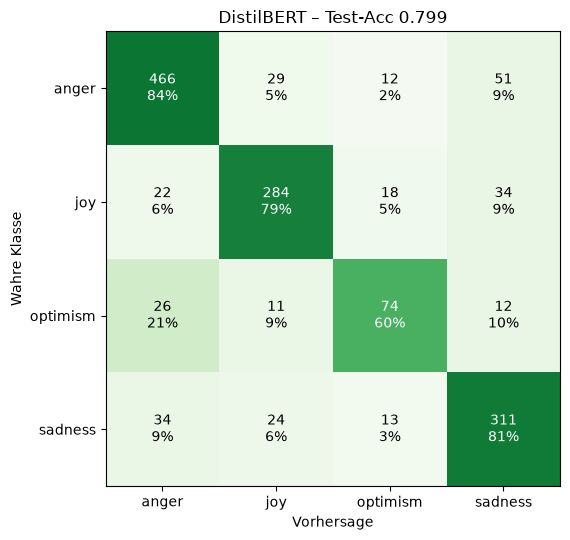

In [14]:
cm = confusion_matrix(test_targets, bert_test["preds"])
cm_norm = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm_norm, cmap="Greens", vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j]:.0%}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xticks(range(NUM_CLASSES), CLASSES)
ax.set_yticks(range(NUM_CLASSES), CLASSES)
ax.set_xlabel("Vorhersage")
ax.set_ylabel("Wahre Klasse")
ax.set_title(f"DistilBERT – Test-Acc {bert_test['acc']:.3f}")
plt.tight_layout()
plt.show()

### Beispielvorhersagen (dieselben Sätze wie in Assignment 6)

In [15]:
@torch.no_grad()
def predict_texts(texts):
    bert_model.eval()
    enc = tokenizer([preprocess(t) for t in texts], padding=True, truncation=True, return_tensors="pt").to(DEVICE)
    return bert_model(**enc).logits.softmax(-1).cpu()


A6_SAMPLES = {  # Ausgaben aus assignment6.ipynb
    "I am so happy today, best day ever!": ("joy (99%)", "joy (78%)"),
    "I am not happy at all, this is terrible": ("anger (69%)", "sadness (64%)"),
    "Why does everything always go wrong?! #furious": ("anger (99%)", "anger (98%)"),
    "Tomorrow will be better, never give up": ("optimism (57%)", "optimism (64%)"),
    "I miss you so much, feeling lonely tonight": ("sadness (84%)", "sadness (94%)"),
}
probs = predict_texts(list(A6_SAMPLES))
for (text, (lstm, gru)), p in zip(A6_SAMPLES.items(), probs):
    print(f"{text:48s} → LSTM: {lstm:14s} | GRU: {gru:14s} | DistilBERT: {CLASSES[p.argmax()]} ({p.max():.0%})")

print("\nTest-Tweets, die in Assignment 6 von LSTM falsch klassifiziert wurden:")
test_texts = splits["test"][0]
for snippet in ["#Deppression is real", "Interesting choice of words", "What makes you feel #joyful",
                "i am revolting", "#cmbyn does screen", "Pressured."]:
    idx = next(i for i, t in enumerate(test_texts) if snippet in t)
    print(f"  wahr={CLASSES[test_targets[idx]]:8s} DistilBERT={CLASSES[bert_test['preds'][idx]]:8s} | "
          f"{test_texts[idx][:80]}")

I am so happy today, best day ever!              → LSTM: joy (99%)      | GRU: joy (78%)      | DistilBERT: joy (100%)
I am not happy at all, this is terrible          → LSTM: anger (69%)    | GRU: sadness (64%)  | DistilBERT: sadness (96%)
Why does everything always go wrong?! #furious   → LSTM: anger (99%)    | GRU: anger (98%)    | DistilBERT: anger (100%)
Tomorrow will be better, never give up           → LSTM: optimism (57%) | GRU: optimism (64%) | DistilBERT: optimism (98%)
I miss you so much, feeling lonely tonight       → LSTM: sadness (84%)  | GRU: sadness (94%)  | DistilBERT: sadness (100%)

Test-Tweets, die in Assignment 6 von LSTM falsch klassifiziert wurden:
  wahr=sadness  DistilBERT=sadness  | #Deppression is real. Partners w/ #depressed people truly dont understand the de
  wahr=anger    DistilBERT=anger    | @user Interesting choice of words... Are you confirming that governments fund #t
  wahr=joy      DistilBERT=joy      | What makes you feel #joyful? 
  wahr=anger  

### Exkurs: Attention-Gewichte

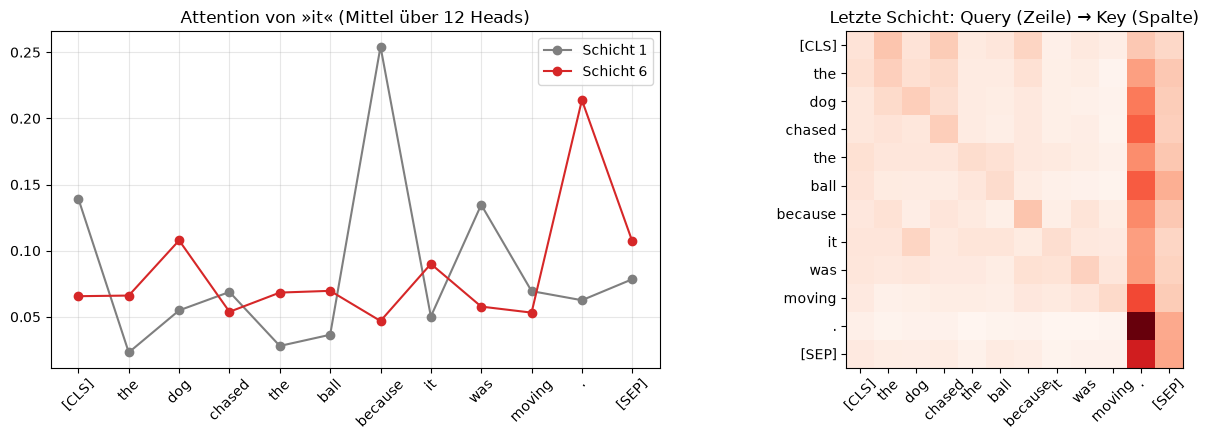

In [16]:
bert_model.set_attn_implementation("eager")  # SDPA liefert keine Attention-Gewichte
sentence = "The dog chased the ball because it was moving."
enc = tokenizer(sentence, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    att = bert_model(**enc, output_attentions=True).attentions  # Tupel: Schicht × (B, Heads, T, T)
bert_model.set_attn_implementation("sdpa")
toks = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
it = toks.index("it")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.2]})
for layer, c in [(0, "tab:gray"), (len(att) - 1, "tab:red")]:
    w = att[layer][0].mean(0)[it].cpu().numpy()
    axes[0].plot(range(len(toks)), w, marker="o", c=c, label=f"Schicht {layer + 1}")
axes[0].set_xticks(range(len(toks)), toks, rotation=45)
axes[0].set_title("Attention von »it« (Mittel über 12 Heads)")
axes[0].legend()
axes[0].grid(alpha=0.3)
m = att[-1][0].mean(0).cpu().numpy()
axes[1].imshow(m, cmap="Reds")
axes[1].set_xticks(range(len(toks)), toks, rotation=45)
axes[1].set_yticks(range(len(toks)), toks)
axes[1].set_title("Letzte Schicht: Query (Zeile) → Key (Spalte)")
plt.tight_layout()
plt.show()